# Exploratory Data Analysis: E-Commerce Customer Support Complaints

**Team project:** classify e-commerce customer-support complaints into 16 `Category` labels, comparing a classical TF-IDF baseline against a transformer-embeddings approach.

**This notebook's role:** explore the dataset *before* any modeling happens, to understand its shape, spot the class imbalance the whole project studies, and motivate the project's hypothesis with real evidence — not just assumption.

**Dataset:** `ecommerce_customer_support_cleaned.csv` — 1,334 customer complaints, with columns `Complaint` (text), `Category` (16 labels), `Urgency` (4 levels).


## 1. Imports

In [1]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_style('whitegrid')
print("Libraries loaded.")


Libraries loaded.


## 2. Load & Initial Exploration

In [2]:
df = pd.read_csv('../data/ecommerce_customer_support_cleaned.csv')

print("Shape:", df.shape)
df.head()


Shape: (1334, 3)


,Complaint,Category,Urgency
0,I can’t add a new address — button does nothing.,Account & Shipping,Low
1,Flash sale prices aren’t reflected during chec...,Promotions,Immediate
2,System declined my payment without any reason....,Payments,Immediate
3,The shipping company marked it as delivered to...,Order Tracking,Medium
4,Site logs me out randomly. which is unacceptable,Technical Issues,Medium


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1334 entries, 0 to 1333
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Complaint  1334 non-null   str  
 1   Category   1334 non-null   str  
 2   Urgency    1334 non-null   str  
dtypes: str(3)
memory usage: 114.7 KB


In [4]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())


Missing values:
 Complaint    0
Category     0
Urgency      0
dtype: int64

Duplicate rows: 0


## 3. Category Distribution

The `Category` column is the classification target for the modeling notebooks. First question: how balanced is it?

Category
Promotions            137
Order Tracking        130
Payments              120
Shipping              108
Account               106
Product Quality       105
Special Requests      104
Inventory             103
Returns                99
Checkout               98
Subscriptions          97
Product Issues         29
Order Issues           29
Technical Issues       25
Account & Shipping     24
Refunds                20
Name: count, dtype: int64


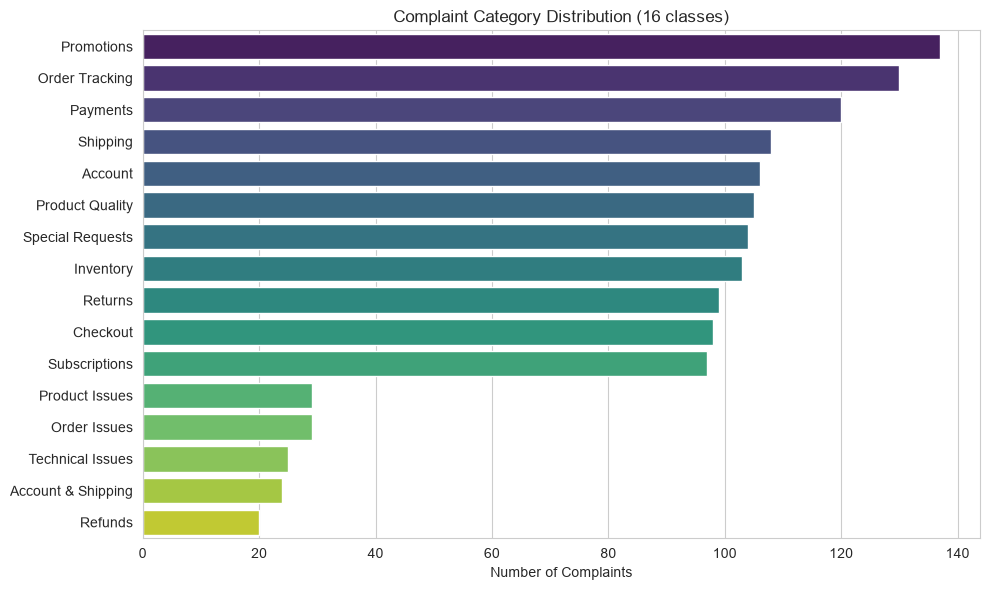

In [5]:
category_counts = df['Category'].value_counts()
print(category_counts)

plt.figure(figsize=(10, 6))
sns.barplot(x=category_counts.values, y=category_counts.index, hue=category_counts.index,
            palette='viridis', legend=False)
plt.title('Complaint Category Distribution (16 classes)')
plt.xlabel('Number of Complaints')
plt.ylabel('')
plt.tight_layout()
plt.show()


In [6]:
# Interpretation
largest = category_counts.idxmax()
smallest = category_counts.idxmin()
ratio = category_counts.max() / category_counts.min()

print(
    f"'{largest}' is the largest category ({category_counts.max()} complaints), "
    f"'{smallest}' is the smallest ({category_counts.min()} complaints) — "
    f"a {ratio:.1f}x imbalance between the biggest and smallest category.\n"
    f"This is the class imbalance the modeling notebooks need to handle explicitly "
    f"(e.g. via class_weight='balanced'), and why macro F1 rather than plain accuracy "
    f"is used as the project's primary metric."
)


'Promotions' is the largest category (137 complaints), 'Refunds' is the smallest (20 complaints) — a 6.8x imbalance between the biggest and smallest category.
This is the class imbalance the modeling notebooks need to handle explicitly (e.g. via class_weight='balanced'), and why macro F1 rather than plain accuracy is used as the project's primary metric.


## 4. Urgency Distribution

`Urgency` isn't the classification target for this project, but it's worth a quick look — it may correlate with category in informative ways.

Urgency
High         563
Medium       360
Immediate    342
Low           69
Name: count, dtype: int64


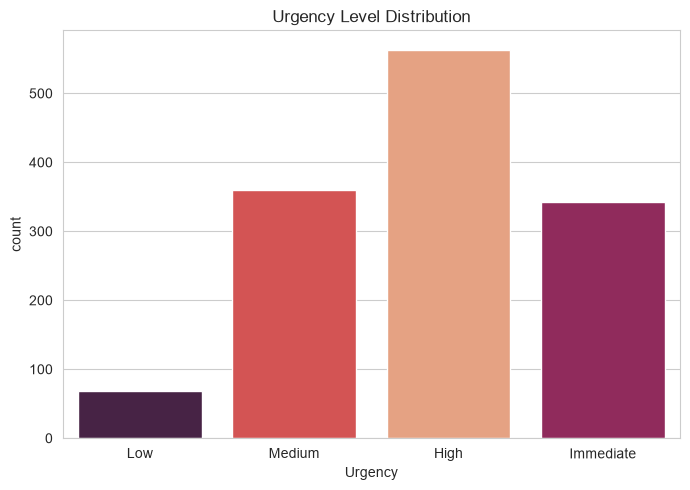

In [7]:
urgency_counts = df['Urgency'].value_counts()
print(urgency_counts)

plt.figure(figsize=(7, 5))
order = ['Low', 'Medium', 'High', 'Immediate']
sns.countplot(x='Urgency', data=df, order=order, hue='Urgency', palette='rocket', legend=False)
plt.title('Urgency Level Distribution')
plt.tight_layout()
plt.show()


## 5. Category vs. Urgency

Is a complaint's category related to how urgent it is? A chi-square test of independence answers this rigorously, not just visually.

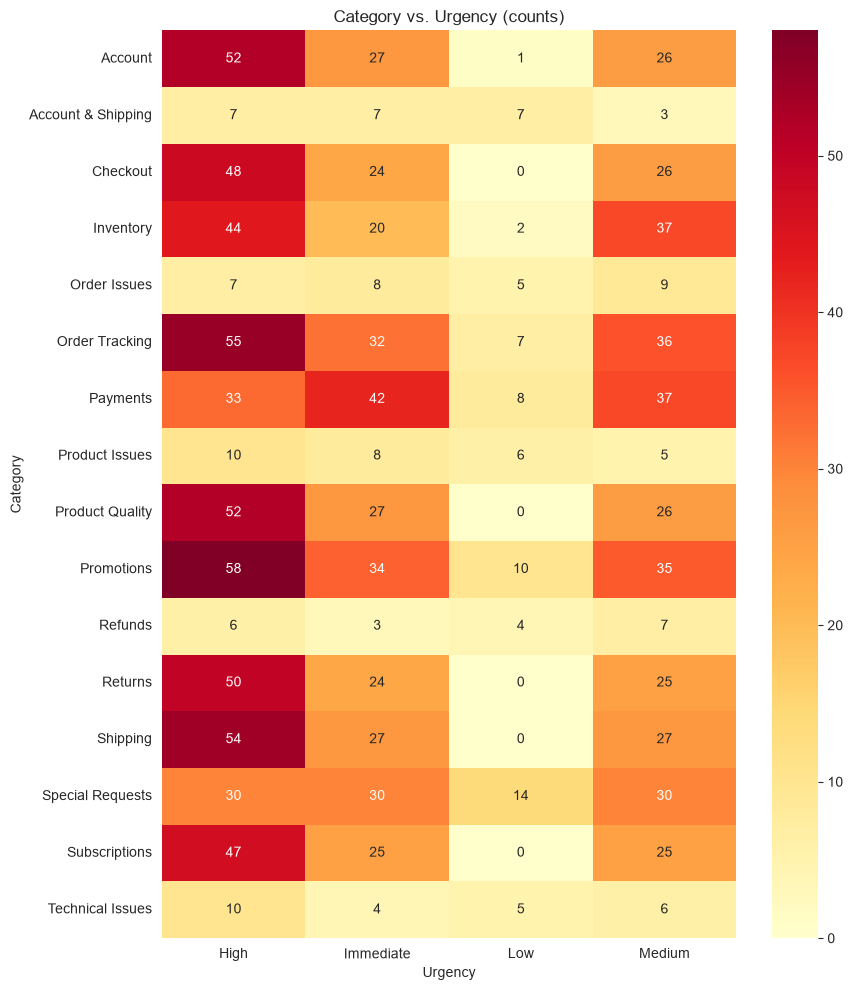

In [8]:
crosstab = pd.crosstab(df['Category'], df['Urgency'])

plt.figure(figsize=(9, 10))
sns.heatmap(crosstab, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Category vs. Urgency (counts)')
plt.tight_layout()
plt.show()


In [9]:
chi2, p_value, dof, expected = chi2_contingency(crosstab)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.4f}")
print()
if p_value < 0.05:
    print("p < 0.05 → Category and Urgency are statistically associated (not independent).")
else:
    print("p >= 0.05 → no strong statistical evidence that Category and Urgency are related.")


Chi-square statistic: 154.22
Degrees of freedom: 45
p-value: 0.0000

p < 0.05 → Category and Urgency are statistically associated (not independent).


## 6. Complaint Text Length

How long are these complaints? This matters for the modeling notebooks — the transformer approach truncates/pads to a fixed length, and very short complaints may carry less signal for either approach.

count    1334.000000
mean        6.967766
std         2.990810
min         3.000000
25%         5.000000
50%         6.000000
75%         7.000000
max        20.000000
Name: word_count, dtype: float64


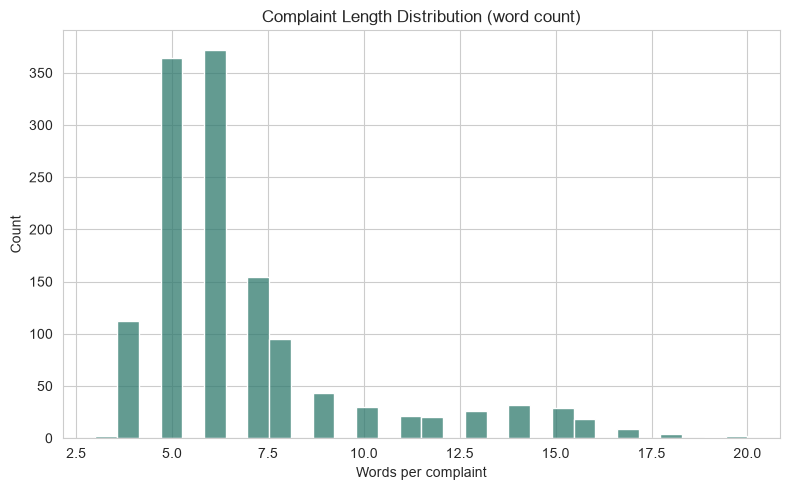

In [10]:
df['word_count'] = df['Complaint'].astype(str).apply(lambda t: len(t.split()))

print(df['word_count'].describe())

plt.figure(figsize=(8, 5))
sns.histplot(df['word_count'], bins=30, color='#2f7a6d')
plt.title('Complaint Length Distribution (word count)')
plt.xlabel('Words per complaint')
plt.tight_layout()
plt.show()


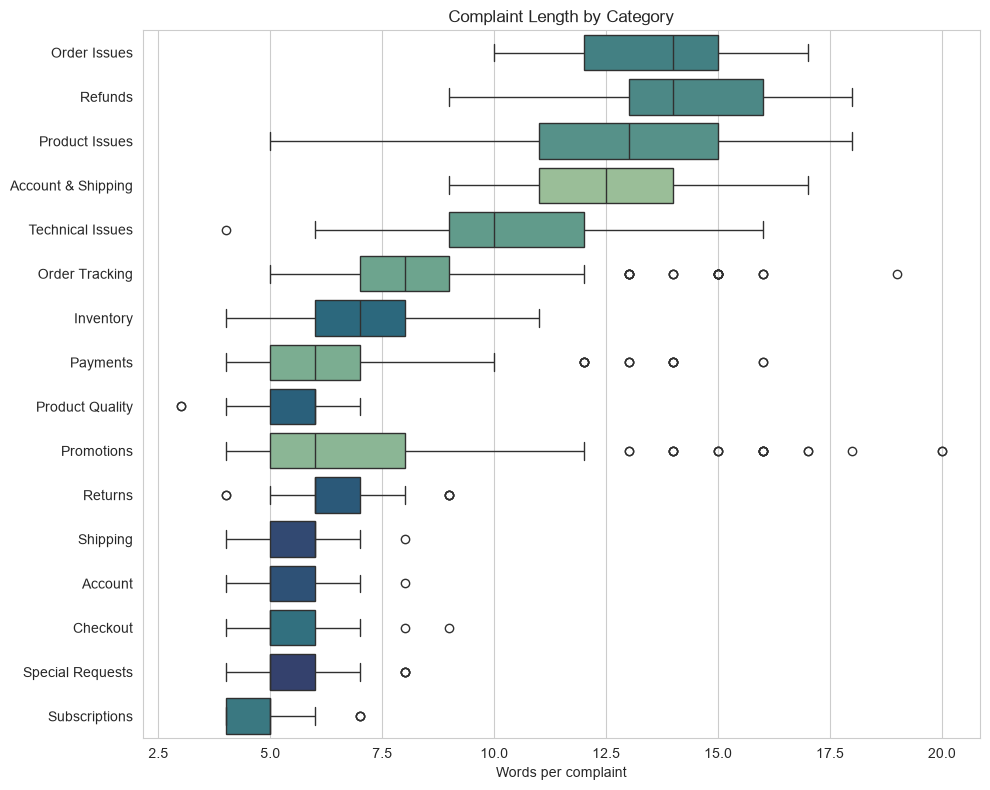

In [11]:
plt.figure(figsize=(10, 8))
order = df.groupby('Category')['word_count'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='word_count', y='Category', order=order, hue='Category',
            palette='crest', legend=False)
plt.title('Complaint Length by Category')
plt.xlabel('Words per complaint')
plt.ylabel('')
plt.tight_layout()
plt.show()


## 7. Most Common Words (Overall and by Category)

A simple word-frequency check — this is the "plain counting" view that TF-IDF formalizes, and it hints at which categories might be easy (distinctive vocabulary) vs. hard (overlapping vocabulary) for either modeling approach.

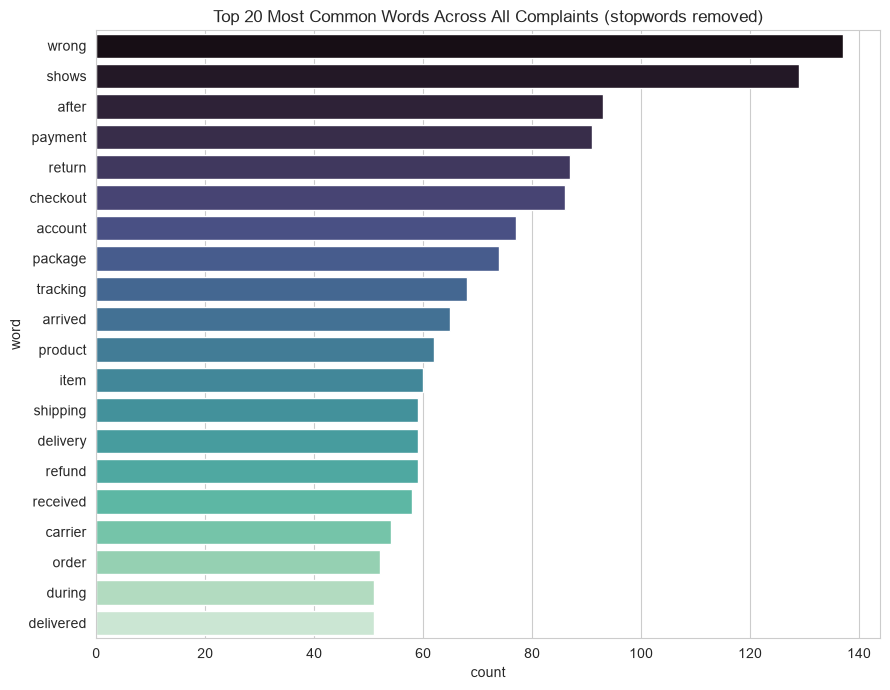

In [12]:
def clean_and_tokenize(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    return text.split()

all_words = []
for complaint in df['Complaint']:
    all_words.extend(clean_and_tokenize(complaint))

STOPWORDS = {'the', 'a', 'an', 'is', 'was', 'were', 'to', 'of', 'and', 'in', 'on',
             'for', 'my', 'it', 'i', 'me', 'this', 'that', 'but', 'with', 'be', 'has',
             'have', 'not', 'im', 'its'}

filtered_words = [w for w in all_words if w not in STOPWORDS and len(w) > 2]
top_words = Counter(filtered_words).most_common(20)

top_words_df = pd.DataFrame(top_words, columns=['word', 'count'])
plt.figure(figsize=(9, 7))
sns.barplot(data=top_words_df, x='count', y='word', hue='word', palette='mako', legend=False)
plt.title('Top 20 Most Common Words Across All Complaints (stopwords removed)')
plt.tight_layout()
plt.show()


In [13]:
# Compare vocabulary overlap between two categories that seem likely to be confused
cat_a, cat_b = 'Payments', 'Checkout'

words_a = set()
words_b = set()
for complaint in df[df['Category'] == cat_a]['Complaint']:
    words_a.update(clean_and_tokenize(complaint))
for complaint in df[df['Category'] == cat_b]['Complaint']:
    words_b.update(clean_and_tokenize(complaint))

overlap = words_a & words_b
print(f"'{cat_a}' unique words: {len(words_a)}")
print(f"'{cat_b}' unique words: {len(words_b)}")
print(f"Shared words between them: {len(overlap)}")
print(f"Overlap ratio: {len(overlap) / min(len(words_a), len(words_b)) * 100:.1f}%")
print()
print("Sample shared words:", list(overlap)[:15])


'Payments' unique words: 306
'Checkout' unique words: 248
Shared words between them: 74
Overlap ratio: 29.8%

Sample shared words: ['oneclick', 'blocked', 'final', 'at', 'message', 'error', 'verification', 'country', 'step', 'mismatch', 'too', 'wrong', 'applied', 'address', 'card']


In [14]:
# Interpretation
print(
    f"'{cat_a}' and '{cat_b}' share a notable portion of their vocabulary — words like "
    f"'card', 'charged', or 'transaction' can plausibly appear in complaints about either. "
    f"This is exactly the kind of semantically overlapping category pair the project's "
    f"hypothesis expects the transformer approach to handle better than pure word-matching "
    f"(TF-IDF), since it can use context and meaning rather than exact word overlap."
)


'Payments' and 'Checkout' share a notable portion of their vocabulary — words like 'card', 'charged', or 'transaction' can plausibly appear in complaints about either. This is exactly the kind of semantically overlapping category pair the project's hypothesis expects the transformer approach to handle better than pure word-matching (TF-IDF), since it can use context and meaning rather than exact word overlap.


## 8. Key Findings Summary

For the modeling teammates:

1. **Class imbalance is real and significant** — categories range from ~20 to ~137 examples. Both modeling notebooks must handle this explicitly (e.g. `class_weight='balanced'`), and macro F1 (not accuracy) should be the primary reported metric.
2. **Category and Urgency show a statistically significant relationship** (see Section 5's chi-square test) — not used directly in the classification task, but useful context.
3. **Complaint length varies by category** — some categories (e.g. more technical ones) tend toward longer complaints; this could interact with how well TF-IDF vs. embeddings perform.
4. **Some categories share substantial vocabulary** (e.g. "Payments" vs. "Checkout") — these are the categories where the project's hypothesis expects the transformer's semantic understanding to provide a real advantage over TF-IDF's exact word-matching.

**Recommended shared setup for both modeling notebooks:** 80/20 stratified split, `random_state=42`, all 16 categories kept unmerged, macro F1 as the primary metric.
